# Baseline Models

The non ML references every model must beat, such as today's business rule. They show what is possible without a model. Every ML model, from simple to complex, is built in `08_training.ipynb`. Every baseline is scored on the same CV folds that model training will use. The test set is not used here.

**How to use this notebook.** The cells marked *Decision* hold the metrics and the baselines. Edit them, then choose Run All. Raw rows are never shown here.

## Setup

Finds the project root, loads the shared spec `ml_spec.yaml`, and checks the kernel. Run this cell first.

In [1]:
import os
import sys
from pathlib import Path

# The project root is the closest folder with ml_spec.yaml. Everything runs from there.
here = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in here if (p / "ml_spec.yaml").is_file()), Path.cwd())
os.chdir(ROOT)
# The project's own code (src) comes from this folder, also in an experiment's worktree, where the editable
# install in .venv would point to the main project.
sys.path.insert(0, str(ROOT))

# Shared code from the ML project skills
sys.path.insert(0, r"/Users/ani/.claude/skills/ml-baseline-model/scripts")
import ml_common
import nb_common
try:  # MLflow tracking, in the ML project skills: keeps a copy of each chart for the stage's run
    import tracking
    tracking.capture_figures()
except ImportError:
    tracking = None

SPEC_PATH = str(ROOT / "ml_spec.yaml")
spec = ml_common.migrate(ml_common.load(SPEC_PATH)) if os.path.exists(SPEC_PATH) else ml_common.template()
PATHS = ml_common.project_paths(spec, str(ROOT))
NOTEBOOK = os.path.join(PATHS["notebooks"], "07_baseline.ipynb")
STAGE = "baseline"

print("Project root:", ROOT)
print("Python:", sys.executable)
if (ROOT / ".venv").is_dir() and Path(sys.prefix).resolve() != (ROOT / ".venv").resolve():
    print("Warning: this kernel is not the project's .venv. Choose 'Select Kernel' and pick the project kernel.")

Project root: /Users/ani/Projects/16_weather_prediction
Python: /Users/ani/Projects/16_weather_prediction/.venv/bin/python


In [2]:
import datetime as dt
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import model_core
import split_core

sys.path.insert(0, str(ROOT))   # the project's own src package
import src.features as F
importlib.reload(F)

<module 'src.features' from '/Users/ani/Projects/16_weather_prediction/src/features.py'>

## What This Builds On

In [3]:
framing, business, split, features = (spec.get(k) or {} for k in ("framing", "business", "split", "features"))
TASK_TYPE, TARGET = framing.get("task_type"), split.get("target")
CONFIG = F.load_config(spec)
INPUTS = F.feature_columns(CONFIG)
success = framing.get("success") or {}
print(f"Task: {TASK_TYPE}. Target: {TARGET}. Inputs: {len(INPUTS)}")
print(f"Current approach: {business.get('current_approach')}")
print(f"Primary metric in the framing: {success.get('primary_metric')}")
print(f"V1 bar: {success.get('v1_bar')}")
blockers = ml_common.modelling_blockers(spec)
print("Modelling may start." if not blockers else "Not ready for modelling: " + "; ".join(blockers))

Task: forecasting. Target: temperature_2m_max. Inputs: 27
Current approach: None
Primary metric in the framing: MAE
V1 bar: MAE at least 10% lower than the best simple baseline (persistence, seasonal naive, or moving average) on CV, and still lower than it on the test set
Modelling may start.


## Load the Training Rows and Folds

The feature table, joined with the other columns of the split's training rows so a business rule can use them. Columns excluded in the framing, and features the leakage check left out, are not allowed in any baseline.

In [4]:
row_id = split.get("row_id_col") or "row_id"
feat = pd.read_parquet(features["files"]["train"])
raw = pd.read_parquet(split["files"]["train"])
extra = [c for c in raw.columns if c not in feat.columns]
data = feat.merge(raw[[row_id] + extra], on=row_id, how="left").reset_index(drop=True)
folds = split_core.cv_splits(data, split)
EXCLUDED = {e["column"]: e.get("reason") for e in (spec.get("data") or {}).get("excluded_cols") or []}
EXCLUDED.update({c: "left out by the leakage check" for c in (features.get("checks") or {}).get("flagged") or []})
print(f"Training rows: {len(data):,}. Folds: {len(folds)}, validation rows per fold: {[len(v) for _, v in folds]}")
if "classification" in str(TASK_TYPE):
    print(f"Base rate of {TARGET}: {data[TARGET].mean():.4f}")

Training rows: 41,150. Folds: 4, validation rows per fold: [4550, 4550, 4550, 4550]


## Metrics

MAE in degrees is the framing's primary metric. RMSE shows the cost of large misses and bias shows whether a baseline runs warm or cold. WAPE was left out because a percentage error is hard to read for temperatures near or below zero.

*`primary` decides which baseline is the reference. Keys: roc_auc, pr_auc, log_loss, brier, recall_at_k, precision_at_k, lift_at_k for classification; rmse, mae, mape, wape, r2, bias for regression and forecasting. The "at k" metrics take `k` (rows) or `k_share` (a share of rows), and `k_per` (a column such as the scoring date, to apply k within each date).*

In [5]:
# Decision
METRICS = {'primary': {'key': 'mae'}, 'secondary': ['rmse', 'bias']}

## Baselines

The project is exploratory and has no current approach, so there is no rule baseline. Persistence is what the learning question names; the seasonal naive and the 28 day moving average are the other simple forecasts. The reference is the best of the three, which the V1 bar is measured against.

*Each baseline has a `name`, `type`, `params`, and `reason`. Types: `prior` (the average), `rule` (a pandas expression, such as `days_since_last_order > 30`), `column` (one column as the score or forecast; `direction` lower or higher), `segment` (the average per segment, `by`, learned on the fold's training rows). ML models belong in model training.*

In [6]:
# Decision
BASELINES = [
    {
        'name': 'naive',
        'kind': 'non_ml',
        'type': 'column',
        'params': {'column': 'temperature_2m_max_lag_2d'},
        'reason': "Persistence: tomorrow equals the last complete day's maximum, 2 days before the target date. The baseline the learning question names.",
    },
    {
        'name': 'seasonal_naive',
        'kind': 'non_ml',
        'type': 'column',
        'params': {'column': 'temperature_2m_max_lag_364d'},
        'reason': 'The maximum on the same date last year (lag 364 days), the seasonal anchor.',
    },
    {
        'name': 'moving_average',
        'kind': 'non_ml',
        'type': 'column',
        'params': {'column': 'temperature_2m_max_roll_28d_mean_shift_2d'},
        'reason': 'The mean maximum over the 28 days ending on the last complete day.',
    },
]

### Reference

The baseline later models are measured against, usually today's approach, because the V1 bar is stated against it. `None` uses the best non ML baseline.

In [7]:
# Decision
REFERENCE = None

## Score Every Baseline on the CV Folds

In [8]:
problems = [p for b in BASELINES for p in model_core.check_model(b, data, INPUTS, EXCLUDED)]
problems += [f"{b['name']} is an ML model ({b['type']}); ML models are built in model training."
             for b in BASELINES if b.get("type") not in model_core.NON_ML_TYPES]
for b in BASELINES:
    b.setdefault("kind", "non_ml")
assert not problems, " ".join(problems)
per_fold, oof = model_core.cross_validate(BASELINES, data, INPUTS, TARGET, folds, METRICS, TASK_TYPE, CONFIG)
summary = model_core.summarise(per_fold, METRICS)
PRIMARY = model_core.metric_label(METRICS["primary"])
display(summary)

naive: 4 folds in 1.0 seconds
seasonal_naive: 4 folds in 0.0 seconds
moving_average: 4 folds in 0.0 seconds


,model,kind,type,mae,rmse,bias,mae std
0,naive,non_ml,column,2.5156,3.5440,0.0051,0.2686
1,moving_average,non_ml,column,2.7740,3.7704,0.0212,0.3133
2,seasonal_naive,non_ml,column,3.3270,4.5368,0.0484,0.5230


### Per Fold

The primary metric in each fold. A baseline whose score moves a lot between folds is less reliable as a reference.

fold,0,1,2,3
model,,,,
moving_average,2.8991,2.3079,2.9037,2.9853
naive,2.7283,2.1881,2.4038,2.7424
seasonal_naive,3.4624,2.7049,3.1850,3.9557


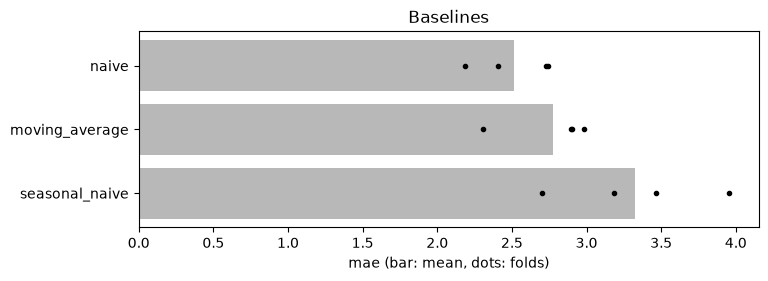

In [9]:
display(per_fold.pivot(index="model", columns="fold", values=PRIMARY).round(4))
fig, ax = plt.subplots(figsize=(8, 0.45 * len(summary) + 1.2))
order = summary["model"].tolist()[::-1]
for i, name in enumerate(order):
    vals = per_fold.loc[per_fold.model == name, PRIMARY]
    ax.barh(i, vals.mean(), color="#3b75af" if name == REFERENCE else "#b8b8b8")
    ax.plot(vals, [i] * len(vals), "k.", markersize=6)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel(PRIMARY + " (bar: mean, dots: folds)")
ax.set_title("Baselines" + (f": the reference, {REFERENCE}, in blue" if REFERENCE else ""))
plt.show()

## Checks

1. A baseline score that is too good to be true usually means a column leaks the outcome.
2. When another non ML baseline beats the reference, a simpler change to today's approach may already help, and a model must beat that too.
3. Scores should be stable across folds.
4. The "at k" metric must pick fewer rows than each group holds, or every baseline scores the same.

In [10]:
pm = model_core.all_metrics(METRICS)[0]
higher = model_core.HIGHER_IS_BETTER.get(pm["key"]) is not False
best_non_ml = summary.head(1)
reference = summary[summary.model == REFERENCE].head(1) if REFERENCE else best_non_ml
assert len(reference), f"REFERENCE {REFERENCE!r} is not one of the baselines."
checks = []
if "classification" in str(TASK_TYPE) and "roc_auc" in summary and summary["roc_auc"].max() > 0.97:
    checks.append(f"An AUC of {summary['roc_auc'].max():.3f} is very high for a baseline. Check the columns it uses for leakage.")
r = reference[PRIMARY].iloc[0]
print(f"Reference: {reference.model.iloc[0]}, {PRIMARY} {r:.4f}")
gain = None
if best_non_ml.model.iloc[0] != reference.model.iloc[0]:
    b = best_non_ml[PRIMARY].iloc[0]
    gain = ((b - r) if higher else (r - b)) / abs(r) * 100 if r else None
    print(f"Best baseline: {best_non_ml.model.iloc[0]}, {PRIMARY} {b:.4f}"
          + (f", {gain:.1f}% better than the reference" if gain is not None else "")
          + ". A simpler change to today's approach may already help, and a model must beat this too.")
std_col = f"{PRIMARY} std"
unstable = summary[(summary[std_col] > 0.2 * summary[PRIMARY].abs()) & summary[std_col].notna()]["model"].tolist()
if unstable:
    checks.append("Scores vary a lot between folds for: " + ", ".join(unstable) + ".")
if pm.get("k_per") and pm.get("k"):
    sizes = pd.concat([data.iloc[v] for _, v in folds]).groupby(pm["k_per"]).size()
    if pm["k"] >= sizes.median():
        checks.append(f"k = {pm['k']:,} is not smaller than the typical {pm['k_per']} group ({sizes.median():,.0f} rows), "
                      "so the at k metric picks every row. Use k_share instead.")
print("Problems: " + (" ".join(checks) if checks else "none found."))

Reference: naive, mae 2.5156
Problems: none found.


## Save the Results

Parquet files in the processed data folder: the metrics per baseline and fold, and the out of fold predictions (one row per training row, fold, and baseline), which model training and error analysis compare against.

In [11]:
os.makedirs(PATHS["data_processed"], exist_ok=True)
files = {"cv_results": os.path.join(PATHS["data_processed"], "baseline_cv_results.parquet"),
         "oof_predictions": os.path.join(PATHS["data_processed"], "baseline_oof_predictions.parquet")}
per_fold.to_parquet(files["cv_results"], index=False)
keys = [c for c in dict.fromkeys([row_id, split.get("date_col"), TARGET]) if c and c in data]
oof_out = oof.join(data[keys], on="position").drop(columns="position")
oof_out.to_parquet(files["oof_predictions"], index=False)
files = {k: ml_common.relpath(v, str(ROOT)) for k, v in files.items()}
print(files)

{'cv_results': 'data/processed/baseline_cv_results.parquet', 'oof_predictions': 'data/processed/baseline_oof_predictions.parquet'}


## Risks, Assumptions, Open Questions, and Decisions

In [12]:
# Decision
risks = []

assumptions = []

open_questions = []

decisions = [
    {
        'decision': 'Baselines are persistence (lag 2), seasonal naive (lag 364), and a 28 day moving average; the reference is the best of them.',
        'reason': 'The project is exploratory, with no current approach; the user chose these three.',
    },
]

resolved_questions = []

## Write to the Spec

Replaces the `baseline` section of `ml_spec.yaml`. Model training reads the metrics, the reference, and the best baseline from there.

In [13]:
pick = lambda frame: {"name": frame.model.iloc[0], PRIMARY: float(frame[PRIMARY].iloc[0])} if len(frame) else None
baseline_section = split_core.plain({
    "metrics": METRICS,
    "primary_label": PRIMARY,
    "models": BASELINES,
    "results": summary.to_dict("records"),
    "reference": pick(reference),
    "best_non_ml": pick(best_non_ml),
    "best_vs_reference_pct": round(gain, 1) if gain is not None else None,
    "files": files,
    "checks": {"problems": checks},
    "run_at": dt.datetime.now().replace(microsecond=0).isoformat(),
})
nb_common.write_stage(SPEC_PATH, "baseline", baseline_section, "ml-baseline-model", assumptions, open_questions, decisions,
                      replace=True)
not_found = nb_common.resolve_questions(SPEC_PATH, resolved_questions, "ml-baseline-model")
if not_found:
    print("These open question IDs were not found: " + ", ".join(map(str, not_found)))
nb_common.record_run(SPEC_PATH, STAGE, NOTEBOOK, "ml-baseline-model")
print("Wrote the baseline section of ml_spec.yaml.")

Wrote the baseline section of ml_spec.yaml.


## Log to MLflow

Logs this run to the project's experiment on the shared MLflow server: the settings, the metrics, the tables, and the charts above, read from what this notebook just wrote to the spec. The run is marked as the current one for this stage. When the server is not reachable, nothing is logged and the notebook still finishes.

In [14]:
MLFLOW_RUN = tracking.log_stage(SPEC_PATH, STAGE, NOTEBOOK, "ml-baseline-model") if tracking else None

MLflow: logged the baseline run to ml/16-weather-prediction: http://127.0.0.1:5000/#/experiments/5/runs/a29766da35b84d939f06399a06f82cfb


## Next Step

Run `/ml-model-training`. It builds the ML models, from simple (logistic or ridge regression) to complex (tuned gradient boosting), on the same folds and metrics, and compares every one with the reference and the best baseline above. Check progress with `/ml-status`.